# Breast cancer analysis

Sklearn can be very useful for data analysis in Python/Jupyter

## Information obtained from Kaggle

#### Project done by Miguel Estrada

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
import numpy as np

In [ ]:
#Importing the data
data_measures = pd.read_csv('data.csv')
data_measures.head(2)

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN


In [71]:
data_measures.drop('id', axis=1, inplace=True)

In [72]:
data_measures.tail()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
564,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,NaN
565,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,NaN
566,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,NaN
567,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,NaN
568,B,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,0.1587,...,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.0000,0.2871,0.07039,NaN


In [73]:
data_measures.isna().sum()

diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_worst      0
Unnamed: 32                569
dtype: i

In [74]:
data_measures.drop('Unnamed: 32', axis=1, inplace=True)

In [75]:
data_measures.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [76]:
df_clean = data_measures.copy()
df_clean["diagnosis_label"] = data_measures["diagnosis"].map({
    "B": "Benign (B)",
    "M": "Malignant (M)",
})

order_labels = ["Benign (B)", "Malignant (M)"]
palette_map = {"Benign (B)": "#4C72B0", "Malignant (M)": "#DD8452"}


C:\Users\Miguel Estrada\AppData\Local\Temp\ipykernel_4828\324902610.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
C:\Users\Miguel Estrada\AppData\Local\Temp\ipykernel_4828\324902610.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
C:\Users\Miguel Estrada\AppData\Local\Temp\ipykernel_4828\324902610.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
C:\Users\Miguel Estrada\AppData\Local\Temp\ipykernel_4828\324902610.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.

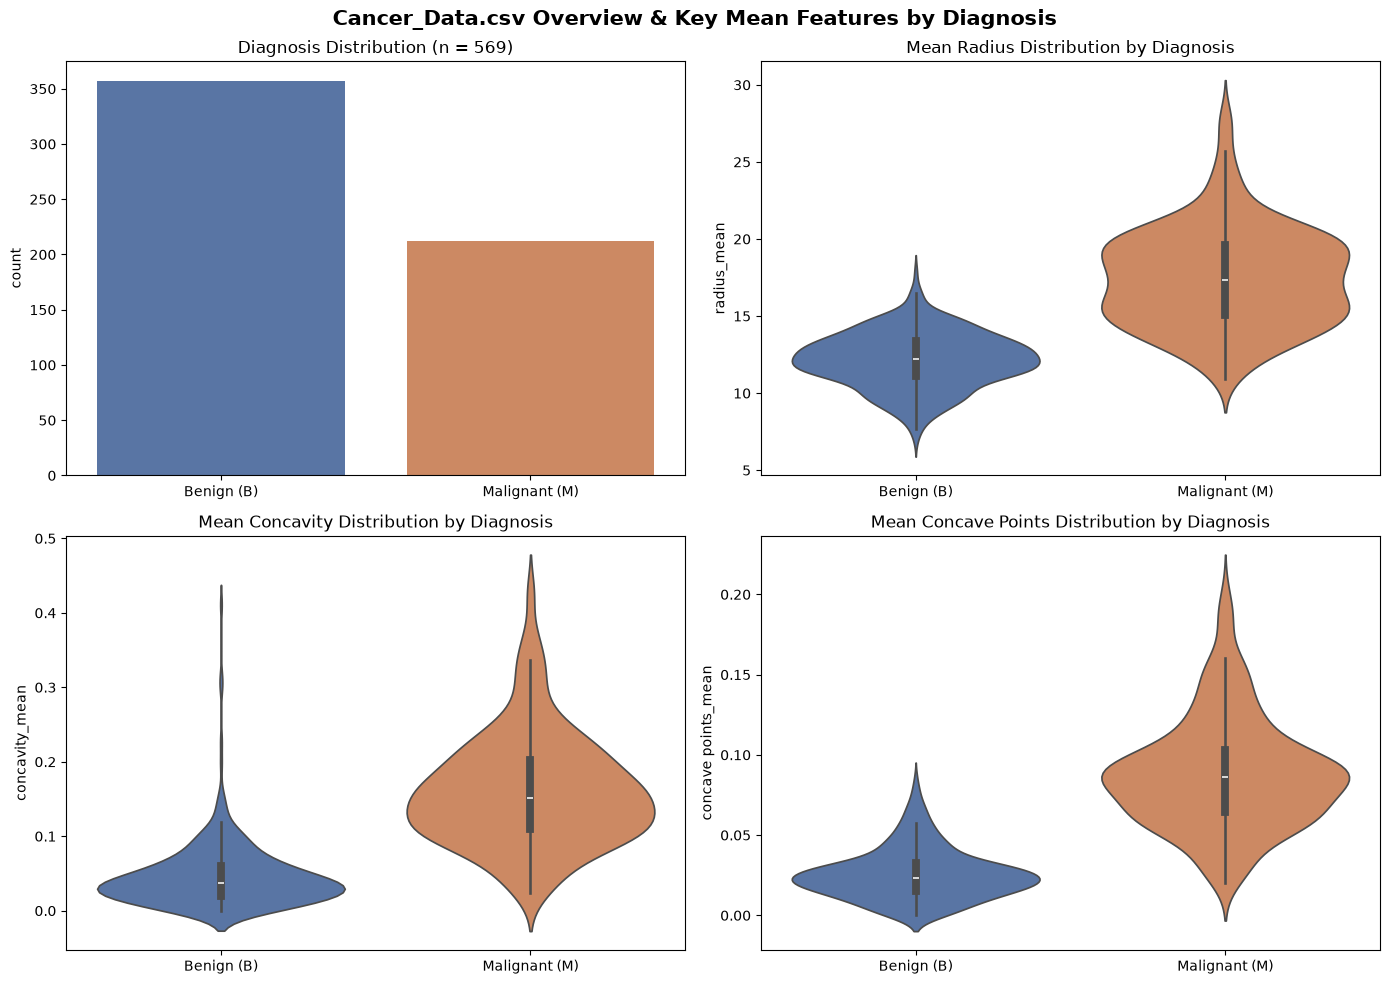

In [77]:
# 2. Diagnosis countplot + key mean feature violin plots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(
    "Cancer_Data.csv Overview & Key Mean Features by Diagnosis",
    fontsize=15,
    fontweight="bold",
)

sns.countplot(
    data=df_clean,
    x="diagnosis_label",
    order=order_labels,
    palette=palette_map,
    ax=axes[0, 0],
)
axes[0, 0].set_title("Diagnosis Distribution (n = 569)")
axes[0, 0].set_xlabel("")

sns.violinplot(
    data=df_clean,
    x="diagnosis_label",
    y="radius_mean",
    order=order_labels,
    palette=palette_map,
    inner="box",
    ax=axes[0, 1],
)
axes[0, 1].set_title("Mean Radius Distribution by Diagnosis")
axes[0, 1].set_xlabel("")

sns.violinplot(
    data=df_clean,
    x="diagnosis_label",
    y="concavity_mean",
    order=order_labels,
    palette=palette_map,
    inner="box",
    ax=axes[1, 0],
)
axes[1, 0].set_title("Mean Concavity Distribution by Diagnosis")
axes[1, 0].set_xlabel("")

sns.violinplot(
    data=df_clean,
    x="diagnosis_label",
    y="concave points_mean",
    order=order_labels,
    palette=palette_map,
    inner="box",
    ax=axes[1, 1],
)
axes[1, 1].set_title("Mean Concave Points Distribution by Diagnosis")
axes[1, 1].set_xlabel("")

plt.tight_layout()
plt.show()

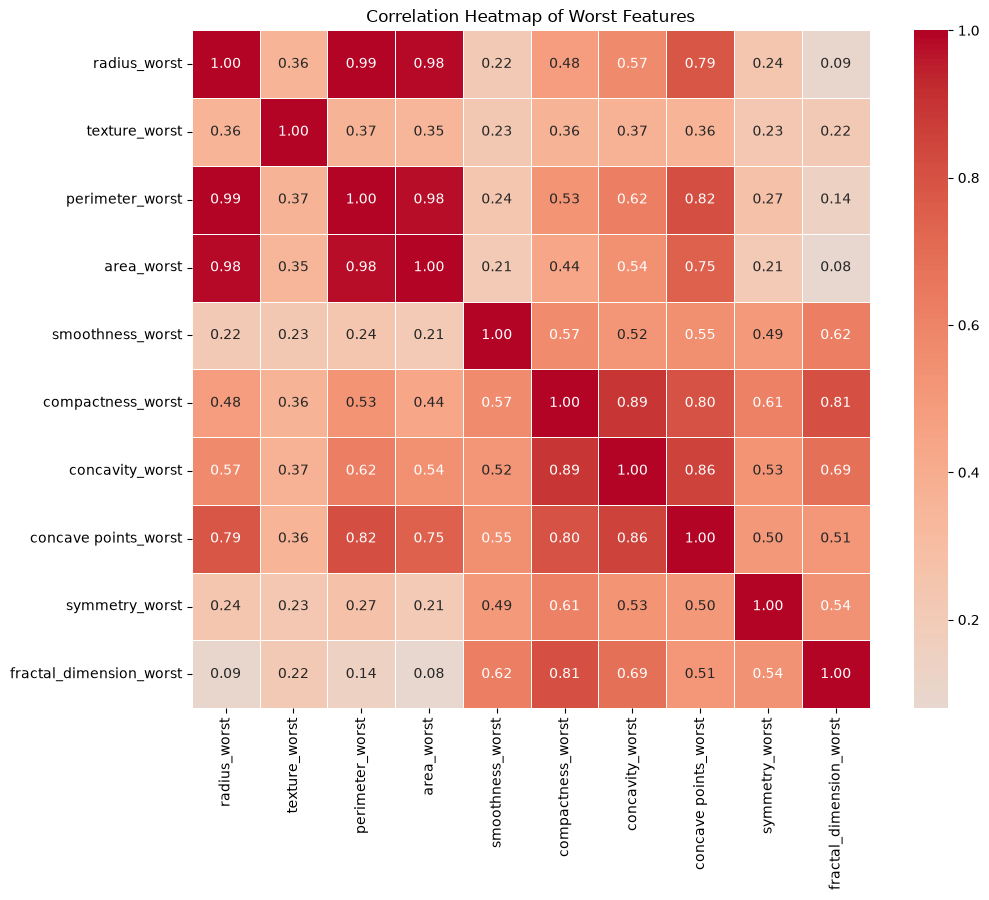

In [78]:
# 3. Correlation heatmap of '_worst' features
worst_cols = [col for col in df_clean.columns if col.endswith("_worst")]
plt.figure(figsize=(11, 9))
sns.heatmap(
    df_clean[worst_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5,
)
plt.title("Correlation Heatmap of Worst Features")
plt.tight_layout()
plt.show()

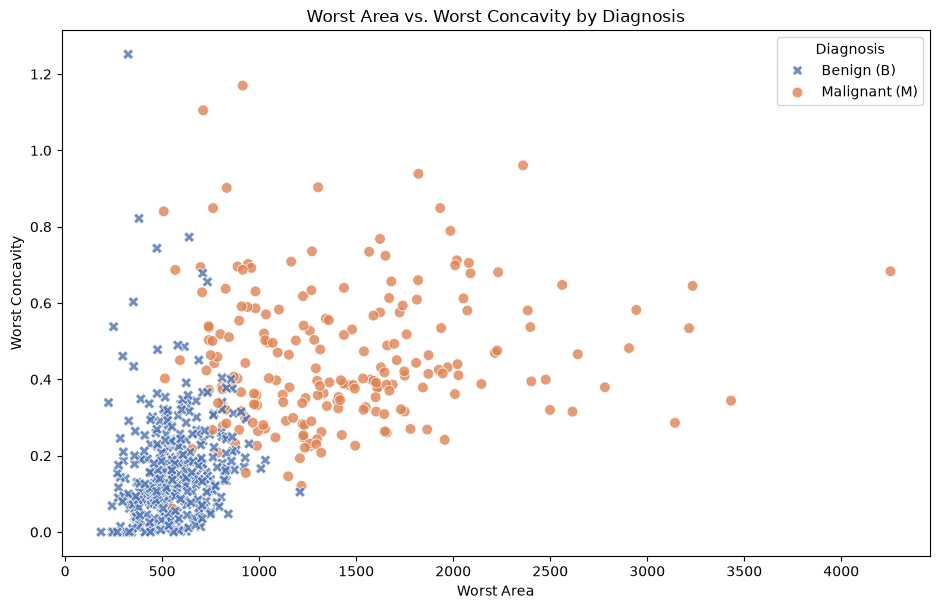

In [79]:
# 4. Scatterplot of area_worst vs concavity_worst
plt.figure(figsize=(9.5, 6.2))
sns.scatterplot(
    data=df_clean,
    x="area_worst",
    y="concavity_worst",
    hue="diagnosis_label",
    style="diagnosis_label",
    hue_order=order_labels,
    palette=palette_map,
    alpha=0.8,
    s=60,
)
plt.title("Worst Area vs. Worst Concavity by Diagnosis")
plt.xlabel("Worst Area")
plt.ylabel("Worst Concavity")
plt.legend(title="Diagnosis")
plt.tight_layout()
plt.show()

In [80]:
from sklearn.preprocessing import LabelEncoder
labelencoder = LabelEncoder()
data_measures_2 = data_measures.copy()
data_measures_2['diagnosis'] = labelencoder.fit_transform(data_measures_2['diagnosis'])
data_measures_2.sample(5)

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
457,0,13.21,25.25,84.10,537.9,0.08791,0.05205,0.02772,0.02068,0.1619,...,14.35,34.23,91.29,632.9,0.1289,0.1063,0.1390,0.06005,0.2444,0.06788
80,0,11.45,20.97,73.81,401.5,0.11020,0.09362,0.04591,0.02233,0.1842,...,13.11,32.16,84.53,525.1,0.1557,0.1676,0.1755,0.06127,0.2762,0.08851
267,0,13.59,21.84,87.16,561.0,0.07956,0.08259,0.04072,0.02142,0.1635,...,14.80,30.04,97.66,661.5,0.1005,0.1730,0.1453,0.06189,0.2446,0.07024
500,0,15.04,16.74,98.73,689.4,0.09883,0.13640,0.07721,0.06142,0.1668,...,16.76,20.43,109.70,856.9,0.1135,0.2176,0.1856,0.10180,0.2177,0.08549
388,0,11.27,15.50,73.38,392.0,0.08365,0.11140,0.10070,0.02757,0.1810,...,12.04,18.93,79.73,450.0,0.1102,0.2809,0.3021,0.08272,0.2157,0.10430


# Analysis with all the variables
Trying to predict the gender which height and weight as data

In [81]:
X = data_measures_2.drop('diagnosis', axis=1)
Y = data_measures_2['diagnosis']

In [82]:
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.2)

In [83]:
classifier = LogisticRegression(fit_intercept=True)
classifier.fit(x_train, y_train)

C:\Users\Miguel Estrada\AppData\Roaming\Python\Python314\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

## Logistic Regression: coefficients and feature importance

The model coefficients show how each standardized variable affects the log-odds of predicting the positive class. Because `Height` and `Weight` are standardized using the training data, their coefficient magnitudes can be compared directly.

- **Coefficient:** direction and strength of the relationship with the positive class.
- **Odds ratio:** `exp(coefficient)`, the multiplicative change in the odds for a one-standard-deviation increase in that variable.
- **Relative importance:** each variable's absolute coefficient divided by the sum of absolute coefficients. This is a coefficient-based comparison, not a causal measure.

In [84]:
# Get the feature names and logistic regression coefficients
feature_names = X.columns

coefficient_values = classifier.coef_[0]

# Build a table with coefficients and odds ratios
coefficient_analysis = pd.DataFrame({
    'Variable': feature_names,
    'Coefficient': coefficient_values,
    'Absolute Coefficient': np.abs(coefficient_values),
    'Odds Ratio (per 1 SD)': np.exp(coefficient_values)
})

# Calculate each variable's relative importance
coefficient_analysis['Relative Importance (%)'] = (
    coefficient_analysis['Absolute Coefficient']
    / coefficient_analysis['Absolute Coefficient'].sum()
) * 100

# Sort variables from most to least important
coefficient_analysis = coefficient_analysis.sort_values(
    by='Absolute Coefficient',
    ascending=False
).reset_index(drop=True)

coefficient_analysis

,Variable,Coefficient,Absolute Coefficient,Odds Ratio (per 1 SD),Relative Importance (%)
0,radius_mean,-1.072705,1.072705,0.342082,14.947585
1,radius_worst,-1.062464,1.062464,0.345603,14.804883
2,concavity_worst,0.758650,0.758650,2.135392,10.571391
3,compactness_worst,0.608243,0.608243,1.837201,8.475549
4,texture_worst,0.533568,0.533568,1.705006,7.434995
5,texture_mean,-0.450227,0.450227,0.637483,6.273677
6,texture_se,-0.427633,0.427633,0.652050,5.958846
7,perimeter_mean,-0.271967,0.271967,0.761879,3.789721
8,concavity_mean,0.269493,0.269493,1.309301,3.755248
9,perimeter_worst,0.249232,0.249232,1.283039,3.472912


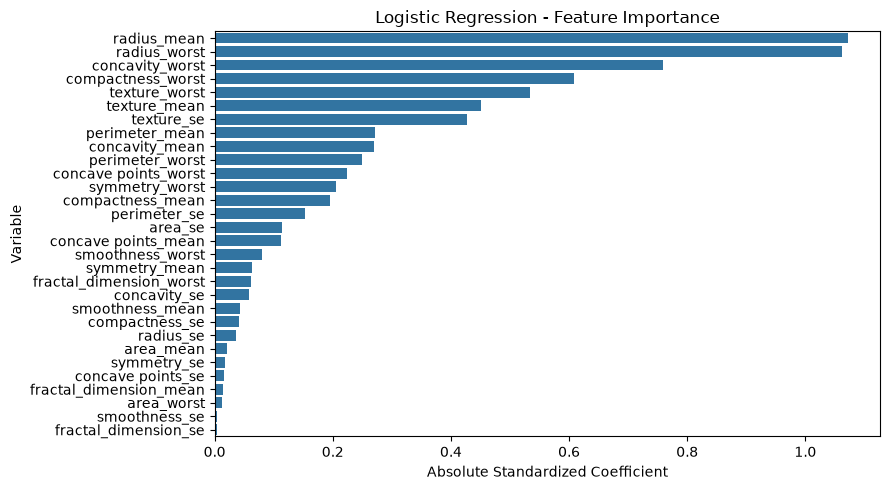

In [85]:
# Visualize coefficient-based feature importance
plt.figure(figsize=(9, 5))

sns.barplot(
    data=coefficient_analysis,
    x='Absolute Coefficient',
    y='Variable'
)

plt.title('Logistic Regression - Feature Importance')
plt.xlabel('Absolute Standardized Coefficient')
plt.ylabel('Variable')
plt.tight_layout()
plt.show()

In [86]:
predictions = classifier.predict(x_test)

<Axes: >

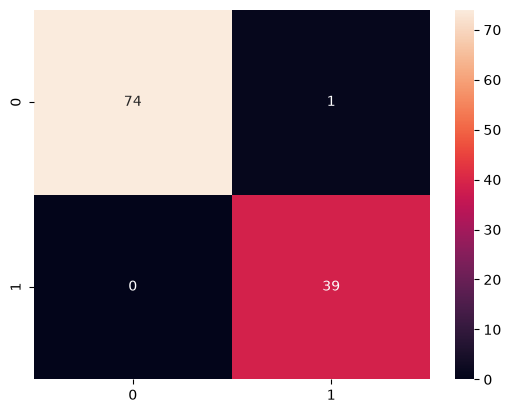

In [87]:
cm = confusion_matrix(y_test, predictions)
sns.heatmap(cm, annot=True)

In [93]:
# Place original labels in a neighboring column
data_measures_2['diagnosis_original'] = labelencoder.inverse_transform(data_measures_2['diagnosis'])

print(data_measures_2[['diagnosis', 'diagnosis_original']].sample(10))
""""
B: 0
M: 1
"""

     diagnosis diagnosis_original
407          0                  B
67           0                  B
549          0                  B
364          0                  B
254          1                  M
452          0                  B
477          0                  B
541          0                  B
137          0                  B
212          1                  M


'"\nB: 0\nM: 1\n'

In [ ]:
## Accuracy of the model
accuracy_score(y_test, predictions)

0.9210526315789473

In [ ]:
from sklearn.metrics import classification_report
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       0.95      0.93      0.94        74
           1       0.88      0.90      0.89        40

    accuracy                           0.92       114
   macro avg       0.91      0.92      0.91       114
weighted avg       0.92      0.92      0.92       114



In [ ]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

mean_squared_error_ = mean_squared_error(y_test, predictions)
r2_score_ = r2_score(y_test, predictions)
mean_absolute_error_ = mean_absolute_error(y_test, predictions)

print("Mean Squared Error: {}".format(mean_squared_error_))
print("R2 score: {}".format(r2_score_))
print("Mean Absolute Error: {}".format(mean_absolute_error_))

Mean Squared Error: 0.07894736842105263
R2 score: 0.6533783783783784
Mean Absolute Error: 0.07894736842105263
